# Sentiment classification with machine learning models (Task 2)

This notebook compares the models of the course on the same data and the same protocol:

- **Ch3, *Analyse des sentiments***: preprocessing (stop words, lemmatisation, stemming), text representations (TF-IDF, improved Delta TF-IDF, word2vec weighted by Delta TF-IDF), classifiers Naive Bayes (NB), linear SVM, Maximum Entropy (ME = logistic regression) and their majority vote;
- **Ch4, *Perceptron multicouches* and RNN**: a multilayer perceptron, a simple RNN, an LSTM and the CNN + LSTM hybrid shown in Ch3.

**Protocol.** The training file is deduplicated (conflicting labels removed) and split into 90 % train / 10 % validation, stratified, seed 42. Preprocessing and hyper-parameters are chosen by 5-fold cross-validation on the train part; the RNNs use early stopping on the validation part. The test file is used only for the final comparison.

**Metrics.** The test set has a different class balance from the training set (32 % negative vs 16 %), so accuracy is misleading. We report the **macro-F1** (main metric), the **macro-recall** (official metric of SemEval-2017 Task 4A, which used this test set) and **F1-PN**, the mean F1 of the positive and negative classes.

The heavy steps (cross-validation, grid search, RNN training) are run by `scripts/run_task2_models.py` and `scripts/run_task2_neural.py`. By default this notebook reads their saved tables and models; set `RETRAIN = True` to refit everything here (about 30 minutes on a laptop CPU).

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src" / "tweet_sentiment").is_dir())
sys.path.insert(0, str(root / "src"))

from tweet_sentiment.config import FIGURES, MODELS, TABLES, ensure_output_dirs
from tweet_sentiment.data import load_model_data
from tweet_sentiment.evaluation import plot_confusions, plot_model_comparison, scores, top_features
from tweet_sentiment.features import DeltaTfidfVectorizer, delta_idf
from tweet_sentiment.models import PREPROCESSING_VARIANTS, build_models

RETRAIN = False   # True: rerun the CV / grid search and refit every model here

ensure_output_dirs()
pd.set_option("display.max_colwidth", 140)
sns.set_theme(style="whitegrid")
train, val, test = load_model_data()
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,} tweets")
display(pd.DataFrame({s: d["polarity"].value_counts(normalize=True).sort_index().mul(100).round(1)
                      for s, d in (("train", train), ("validation", val), ("test", test))}))

train 44,478 | validation 4,943 | test 12,284 tweets


,train,validation,test
polarity,,,
-1,15.6,15.6,32.3
0,44.8,44.8,48.3
1,39.7,39.7,19.3


## 1. Preprocessing (course Ch3)

The course lists three cleaning steps: stop word removal, lemmatisation and stemming. They are implemented in `TextNormalizer`, on top of a light cleaning (lowercase, URLs → `URL`, mentions → `USER`, `#` removed, emoticons → `EMOPOS` / `EMONEG`, "soooo" → "soo"). Negations (*not*, *no*, *don't*…) are never removed as stop words, since Task 1 showed that they are 2-3 times more frequent in negative tweets.

In [2]:
example = train.loc[train["text"].str.len().between(90, 120)].iloc[3, 2]
print("raw:", example, "\n")
for name, norm in PREPROCESSING_VARIANTS.items():
    print(f"{name:26s}", norm(example))

raw: Church was cool, I think I was expecting more though. None the less I'll be back next sunday. 

clean only                 ['church', 'was', 'cool', 'i', 'think', 'i', 'was', 'expecting', 'more', 'though', 'none', 'the', 'less', "i'll", 'be', 'back', 'next', 'sunday']


stop words                 ['church', 'cool', 'think', 'expecting', 'though', 'none', 'less', 'back', 'next', 'sunday']


stop words + lemma         ['church', 'cool', 'think', 'expect', 'though', 'none', 'less', 'back', 'next', 'sunday']
stop words + stem          ['church', 'cool', 'think', 'expect', 'though', 'none', 'less', 'back', 'next', 'sunday']
lemma (stop words kept)    ['church', 'be', 'cool', 'i', 'think', 'i', 'be', 'expect', 'more', 'though', 'none', 'the', 'less', "i'll", 'be', 'back', 'next', 'sunday']


Each variant is evaluated with the same model (ME / logistic regression on TF-IDF uni- and bigrams) by 5-fold cross-validation on the training part.

In [3]:
if RETRAIN:
    import subprocess
    subprocess.run([sys.executable, str(root / "scripts" / "run_task2_models.py")], check=True, cwd=root)
prep = pd.read_csv(TABLES / "task2_preprocessing_comparison.csv", index_col=0)
display(prep.round(4))
ax = prep["cv_macro_f1_mean"].plot.barh(xerr=prep["cv_macro_f1_std"], color="#4C72B0", figsize=(7, 3))
ax.set(xlim=(0.62, 0.65), xlabel="CV macro-F1 (mean ± std over 5 folds)", ylabel="")
plt.show()

,cv_macro_f1_mean,cv_macro_f1_std,vocabulary_size
preprocessing,,,
clean only,0.6381,0.0045,96615
stop words,0.6328,0.0065,66889
stop words + lemma,0.6405,0.0030,67448
stop words + stem,0.6399,0.0034,66960
lemma (stop words kept),0.6430,0.0031,91874


**Interpretation.** Removing stop words shrinks the vocabulary by a third (96 615 → 66 889 terms) but slightly *lowers* the score (0.633 vs 0.638). In tweets of about 20 words, many "empty" words carry sentiment or contrast (*but*, *so*, *too*, *very*, *against*), and TF-IDF already down-weights the truly uninformative ones, as the course notes. Lemmatisation helps a little (0.643 when stop words are kept), stemming about as much. The differences are of the order of the standard deviation between folds (0.003-0.006), so the choice matters less than the model. We keep **lemmatisation without stop word removal** for all the models below.

## 2. Improved Delta TF-IDF (course Ch3)

Each term receives the weight

$$V(w,t) = C(w,t) \times \log_2\left(\frac{|N|\,(P_w + 0.5)}{|P|\,(N_w + 0.5)}\right)$$

where $C(w,t)$ is the count of $w$ in tweet $t$, $|P|, |N|$ the numbers of positive and negative tweets and $P_w, N_w$ the numbers of them containing $w$. The smoothing 0.5 avoids infinite weights for words absent from one class. The cell below checks the implementation against the table of the course slide (t1, t2, t3).

In [4]:
import scipy.sparse as sp
n_pos, n_neg = 1000, 590                       # |N| / |P| = 0.59 as on the slide
y = np.array([1] * n_pos + [-1] * n_neg)
cols = []
for p_w, n_w in ((100, 0), (2, 0), (100, 1)):
    c = np.zeros(len(y)); c[:p_w] = 1; c[n_pos:n_pos + n_w] = 1; cols.append(c)
print("course table : 6.90, 1.57, 5.32")
print("our weights  :", np.round(delta_idf(sp.csr_matrix(np.column_stack(cols)), y), 2))

course table : 6.90, 1.57, 5.32
our weights  : [6.89 1.56 5.3 ]


With three classes the formula can be applied to positive vs negative only (`pos_neg`, neutral tweets ignored when estimating the weights) or once per class against the two others (`ovr`, three blocks of features). The grid search below chooses between the two.

## 3. Hyper-parameter search

5-fold cross-validation on the training part, macro-F1.

In [5]:
grid = pd.read_csv(TABLES / "task2_grid_search.csv")
best = grid.loc[grid.groupby("model")["cv_macro_f1"].idxmax()]
display(best.round(4))
params = json.loads((TABLES / "task2_best_params.json").read_text())
print(params)

,model,params,cv_macro_f1,cv_std
5,ME / logistic regression (TF-IDF),"{""clf__C"": 2.0}",0.6430,0.0031
1,NB (TF-IDF),"{""clf__alpha"": 0.3}",0.6011,0.0035
12,linear SVM (Delta TF-IDF),"{""clf__C"": 0.1, ""vec__scheme"": ""ovr""}",0.6531,0.0032
9,linear SVM (TF-IDF),"{""clf__C"": 0.3}",0.6457,0.0035


{'preprocessing': 'lemma (stop words kept)', 'nb_alpha': 0.3, 'me_C': 2.0, 'svm_C': 0.3, 'delta_svm_C': 0.1, 'delta_scheme': 'ovr', 'w2v_C': 0.3}


**Interpretation.** The one-vs-rest Delta TF-IDF (`ovr`) beats the positive-vs-negative version: the neutral class, which is the largest, gets its own weights. The SVM prefers strong regularisation (small C), which is usual with ~90 000 sparse n-gram features for 44 000 tweets.

## 4. Classical models and multilayer perceptron

Models fitted on the training part with the tuned parameters (loaded from `models/` unless `RETRAIN = True`), evaluated on the validation part and on the test file.

In [6]:
names = list(build_models().keys())
models = {}
for name in names:
    safe = "".join(ch if ch.isalnum() else "_" for ch in name).strip("_").lower()
    path = MODELS / f"task2_{safe}.joblib"
    if path.exists() and not RETRAIN:
        models[name] = joblib.load(path)
    else:
        raise FileNotFoundError(f"{path} missing: run scripts/run_task2_models.py first")

rows, test_preds = [], {}
for name, model in models.items():
    v = scores(val["polarity"], model.predict(val["text"]))
    test_preds[name] = model.predict(test["text"])
    t = scores(test["polarity"], test_preds[name])
    rows.append({"model": name, "val_macro_f1": v["macro_f1"], "test_macro_f1": t["macro_f1"],
                 "test_macro_recall": t["macro_recall"], "test_f1_pn": t["f1_pn"],
                 "test_accuracy": t["accuracy"], "test_recall_neg": t["recall_neg"],
                 "test_recall_neu": t["recall_neu"], "test_recall_pos": t["recall_pos"]})
classical = pd.DataFrame(rows).set_index("model").sort_values("val_macro_f1", ascending=False)
display(classical.round(3))

,val_macro_f1,test_macro_f1,test_macro_recall,test_f1_pn,test_accuracy,test_recall_neg,test_recall_neu,test_recall_pos
model,,,,,,,,
linear SVM (Delta TF-IDF),0.658,0.617,0.614,0.600,0.626,0.598,0.663,0.581
linear SVM (TF-IDF),0.656,0.606,0.606,0.586,0.616,0.567,0.656,0.595
vote NB + SVM + ME (TF-IDF),0.656,0.610,0.611,0.596,0.618,0.608,0.634,0.592
ME / logistic regression (TF-IDF),0.654,0.610,0.613,0.599,0.617,0.635,0.618,0.585
"MLP (TF-IDF, 1 hidden layer)",0.621,0.583,0.592,0.577,0.587,0.628,0.558,0.591
linear SVM (weighted word2vec),0.615,0.566,0.593,0.589,0.565,0.730,0.436,0.613
NB (TF-IDF),0.610,0.585,0.597,0.583,0.587,0.629,0.548,0.615


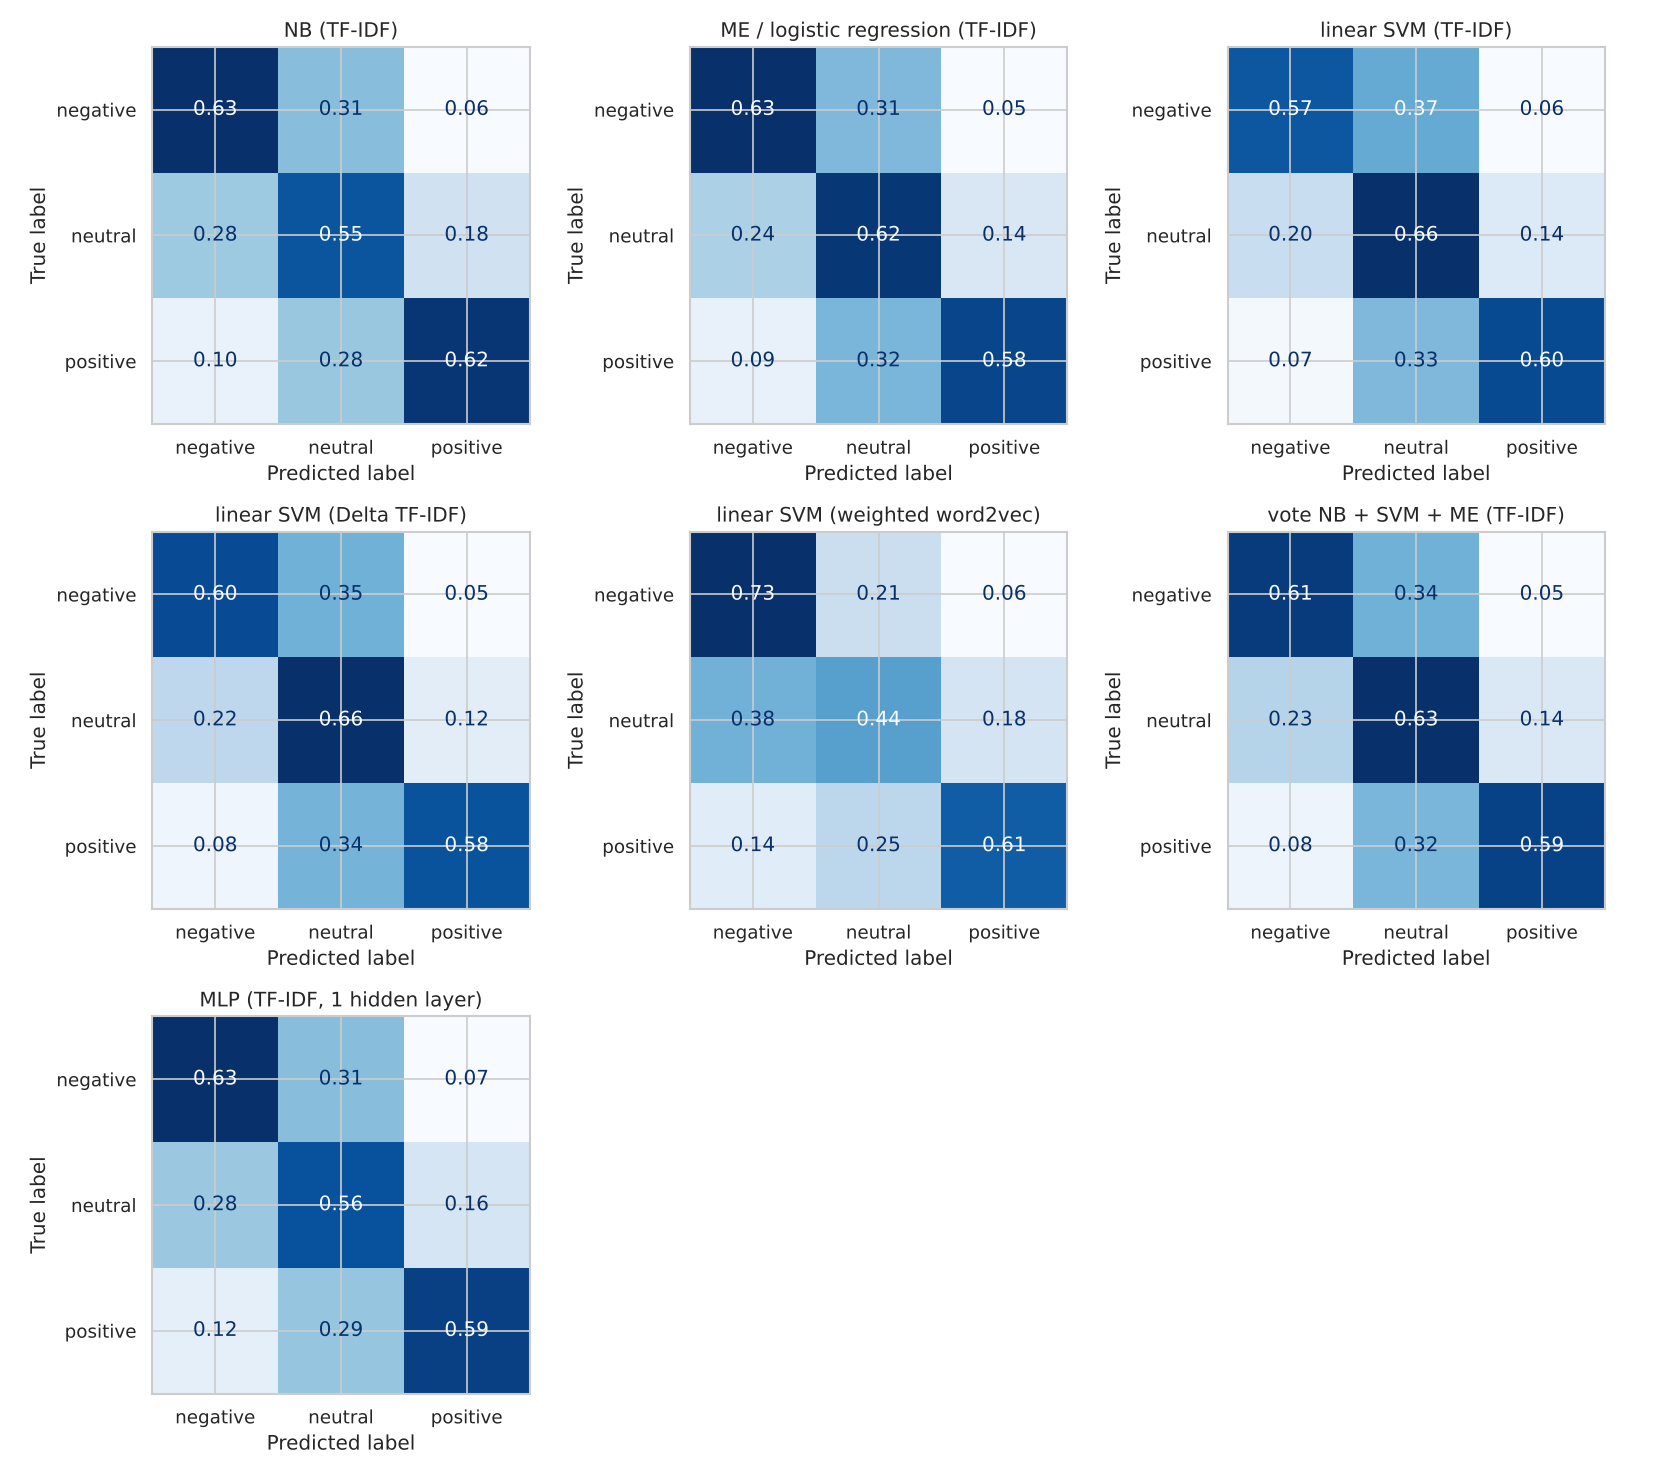

In [7]:
plot_confusions(test_preds, test["polarity"], FIGURES / "task2_classical_confusions.png")
display(Image(FIGURES / "task2_classical_confusions.png"))

**Interpretation.**

- The **linear SVM on Delta TF-IDF** is the best classical model (test macro-F1 0.617, +1.1 points over the same SVM on plain TF-IDF): weighting each n-gram by how unevenly it is spread over the classes, as the course suggests, helps the classifier.
- SVM, ME and their **majority vote** are within half a point of each other. The vote does not beat its best member: NB, SVM and ME see the same TF-IDF features and make largely the same mistakes, so voting has little to correct.
- **Naive Bayes** is the weakest TF-IDF model (0.585), as expected from its independence assumption, but it is by far the fastest to train.
- The **word2vec tweet vector** weighted by Delta TF-IDF (formula of the course) loses the n-gram information: averaging 20 word vectors blurs the sentence, and word2vec trained on 44 000 tweets only gives weak vectors. Its neutral recall drops to 0.44.
- The **multilayer perceptron** (one hidden layer of 256 ReLU units, 30 000 n-grams selected by χ²) overfits within a few epochs (early stopping after 7) and stays below the linear models: with sparse n-grams, a linear separator is already a strong model.
- The confusion matrices show the same pattern for every model: the main error is **neutral ↔ polarised** (21-37 % of negative and positive tweets predicted neutral), while negative ↔ positive confusions are rarer (5-14 %).

In [8]:
me = models["ME / logistic regression (TF-IDF)"]
display(top_features(me, k=15))

,-1 (negative),0 (neutral),1 (positive)
0,fuck (8.48),URL (3.36),happy (8.39)
1,EMONEG (7.55),gucci (3.09),love (8.23)
2,suck (6.18),do you (2.65),great (7.79)
3,shit (5.75),shawn (2.45),EMOPOS (7.52)
4,worst (5.43),murray (2.40),good (7.50)
5,not (5.14),kane (2.25),excite (7.18)
6,kill (5.09),milan (2.04),best (6.63)
7,sad (5.06),last day (2.03),can't wait (6.14)
8,die (4.78),nirvana (2.01),amaze (6.03)
9,stupid (4.71),kpop (2.01),awesome (5.27)


**Interpretation.** The largest ME weights confirm Task 1. Negative and positive tweets are recognised through evaluative words, swear words and emoticons (`EMONEG`, *fuck*, *suck*, *worst*, *not*, *don't* vs `EMOPOS`, *happy*, *love*, *great*, *can't wait*); lemmatisation merges *excited* / *exciting* into *excite*. The neutral class is defined differently: by **topics** (brands and celebrities such as *gucci*, *shawn*, *murray*, *naruto*, *ps4*), by question forms (*do you*, *or*) and by links (`URL`). A model that relies on topic names transfers poorly to a test set about other topics.

## 5. Recurrent networks (course Ch4)

Sentiment analysis is the **many-to-one** case of the course: a sequence of words goes in, one class comes out. All three networks share the same input pipeline: tokens → indices (sequences cut or padded to 50 tokens) → an **Embedding** layer of dimension 100 initialised with a word2vec model trained on the training tweets (fine-tuned during training) → recurrent part → **Dense** softmax layer over the 3 classes.

| Model | Recurrent part |
|---|---|
| simple RNN | `RNN(128, tanh)` |
| LSTM | `LSTM(128)`, gates that keep information over long sequences |
| CNN + LSTM | `Conv1D(128, kernel 3) + MaxPool(2)` then `LSTM(128)` (Othman et al., 2021) |

Training: Adam (lr 2e-3), batch 128, class-weighted cross-entropy, dropout 0.4, gradient clipping at 1 (against exploding gradients), early stopping on validation macro-F1 (patience 2). The networks are written with PyTorch, the layers being those of the Keras examples of the course.

In [9]:
from tweet_sentiment.advanced_models import RNNSentimentClassifier
NAMES = {"rnn": "simple RNN (word2vec init)", "lstm": "LSTM (word2vec init)",
         "cnn_lstm": "CNN + LSTM (word2vec init)"}
if RETRAIN:
    import subprocess
    subprocess.run([sys.executable, str(root / "scripts" / "run_task2_neural.py")], check=True, cwd=root)

rnn_rows, rnn_preds = [], {}
for arch, name in NAMES.items():
    clf = RNNSentimentClassifier.load(MODELS / f"task2_{arch}.pt")
    v = scores(val["polarity"], clf.predict(val["text"]))
    rnn_preds[name] = clf.predict(test["text"])
    t = scores(test["polarity"], rnn_preds[name])
    rnn_rows.append({"model": name, "val_macro_f1": v["macro_f1"], "test_macro_f1": t["macro_f1"],
                     "test_macro_recall": t["macro_recall"], "test_f1_pn": t["f1_pn"],
                     "test_accuracy": t["accuracy"], "test_recall_neg": t["recall_neg"],
                     "test_recall_neu": t["recall_neu"], "test_recall_pos": t["recall_pos"]})
neural = pd.DataFrame(rnn_rows).set_index("model")
display(neural.round(3))

,val_macro_f1,test_macro_f1,test_macro_recall,test_f1_pn,test_accuracy,test_recall_neg,test_recall_neu,test_recall_pos
model,,,,,,,,
simple RNN (word2vec init),0.617,0.572,0.585,0.571,0.575,0.630,0.531,0.593
LSTM (word2vec init),0.650,0.609,0.620,0.613,0.612,0.728,0.545,0.587
CNN + LSTM (word2vec init),0.651,0.612,0.622,0.612,0.617,0.706,0.566,0.595


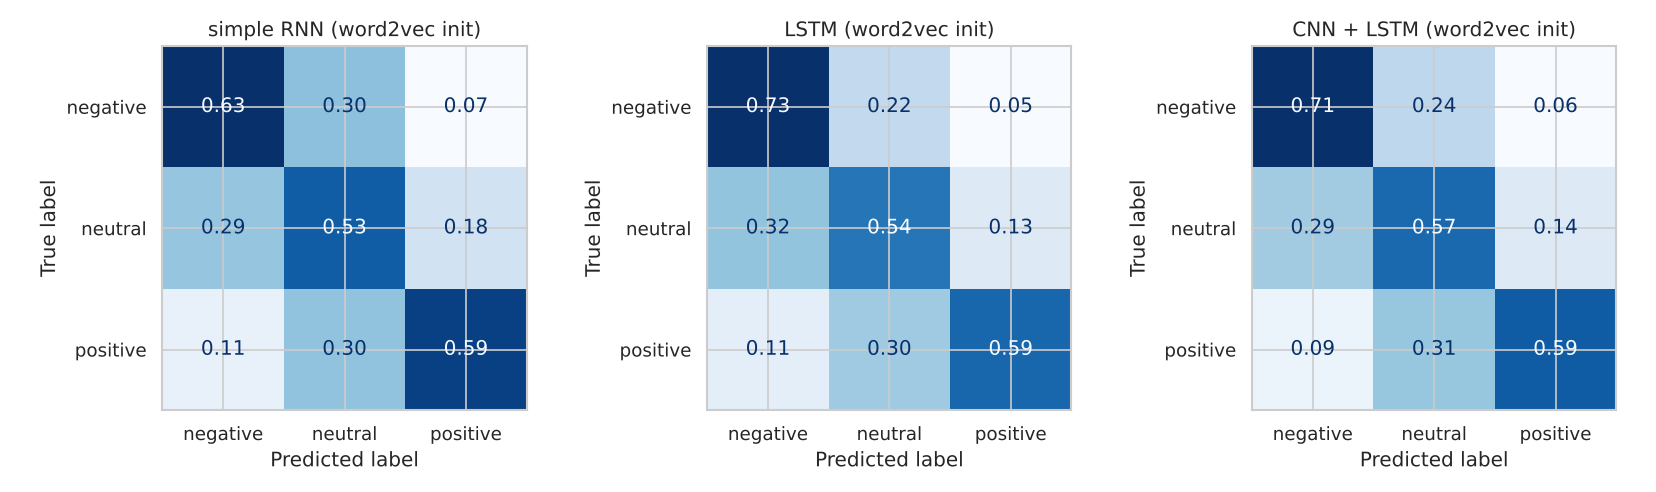

In [10]:
hist = pd.read_csv(TABLES / "task2_neural_training_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in hist.groupby("model", sort=False):
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=name)
    axes[1].plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
axes[0].set(title="Training loss (weighted cross-entropy)", xlabel="epoch")
axes[1].set(title="Validation macro-F1", xlabel="epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES / "task2_neural_training_curves.png", dpi=120)
plt.show()
plot_confusions(rnn_preds, test["polarity"], FIGURES / "task2_neural_confusions.png")
display(Image(FIGURES / "task2_neural_confusions.png"))

**Interpretation.**

- The **simple RNN** is clearly the weakest network (test macro-F1 0.572) and its validation score jumps from one epoch to the next. This is the limit described in Ch4: the gradient flowing back through many tanh steps vanishes, so the network struggles to relate the end of a tweet to its beginning.
- The **LSTM** gains almost 4 points (0.609): its gates let information and gradients go through the whole sequence. The **CNN + LSTM** adds a small gain (0.612) and has the best macro-recall of all models (0.622): the convolution detects local patterns (*not good*, *can't wait*) before the LSTM reads them in order.
- The networks have the best **recall on negative tweets** (0.71-0.73 vs 0.57-0.64 for the linear models), which is what lifts their macro-recall and F1-PN on a test set where negatives are twice as frequent as in training.
- They **overfit quickly**: the training loss keeps falling while the validation score peaks after 1-2 epochs, hence early stopping. With 44 000 training tweets and embeddings learned from them only, the networks do not clearly beat a well-tuned linear model on macro-F1.

## 6. Comparison of all models

,val_macro_f1,test_macro_f1,test_macro_recall,test_f1_pn,test_accuracy
model,,,,,
linear SVM (Delta TF-IDF),0.658,0.617,0.614,0.600,0.626
linear SVM (TF-IDF),0.656,0.606,0.606,0.586,0.616
vote NB + SVM + ME (TF-IDF),0.656,0.610,0.611,0.596,0.618
ME / logistic regression (TF-IDF),0.654,0.610,0.613,0.599,0.617
CNN + LSTM (word2vec init),0.651,0.612,0.622,0.612,0.617
LSTM (word2vec init),0.650,0.609,0.620,0.613,0.612
"MLP (TF-IDF, 1 hidden layer)",0.621,0.583,0.592,0.577,0.587
simple RNN (word2vec init),0.617,0.572,0.585,0.571,0.575
linear SVM (weighted word2vec),0.615,0.566,0.593,0.589,0.565


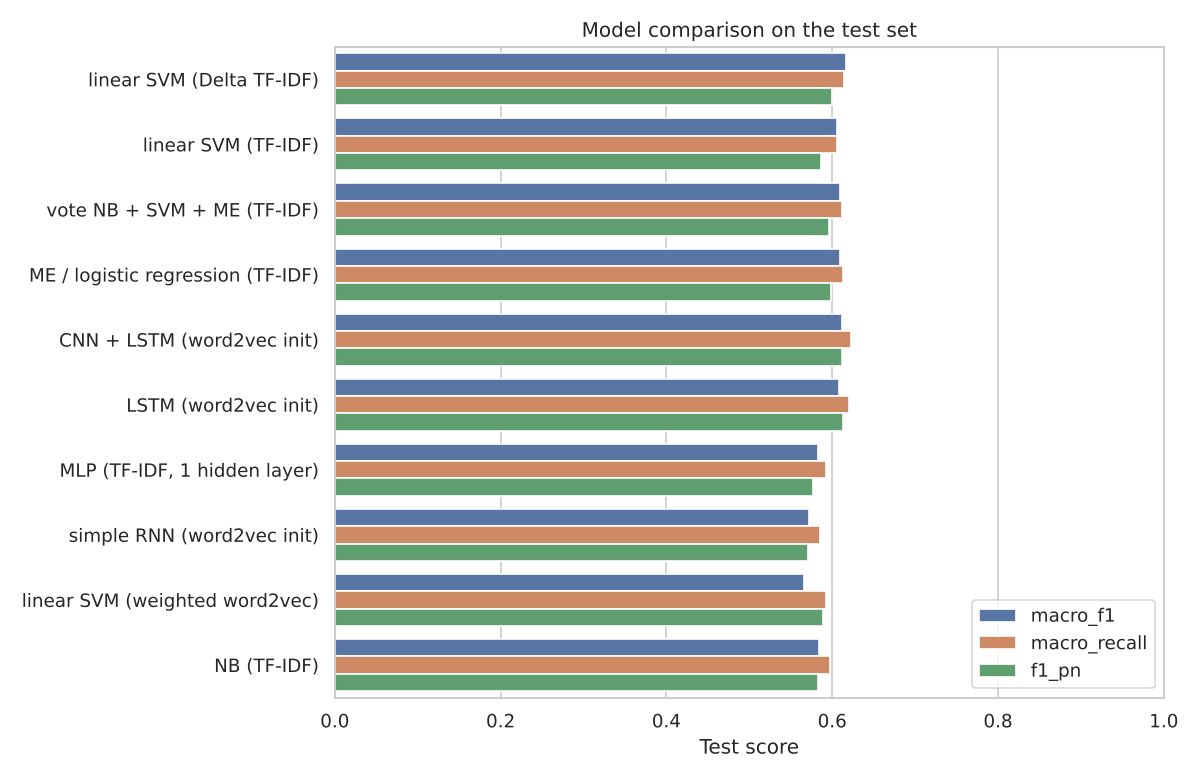

validation - test gap: mean 0.042, min 0.025, max 0.051


In [11]:
allm = pd.concat([classical, neural]).sort_values("val_macro_f1", ascending=False)
display(allm[["val_macro_f1", "test_macro_f1", "test_macro_recall", "test_f1_pn", "test_accuracy"]].round(3))
plot_model_comparison(allm.filter(like="test_").rename(columns=lambda c: c[5:]), FIGURES / "task2_all_models_comparison.png")
display(Image(FIGURES / "task2_all_models_comparison.png"))
gap = (allm["val_macro_f1"] - allm["test_macro_f1"])
print(f"validation - test gap: mean {gap.mean():.3f}, min {gap.min():.3f}, max {gap.max():.3f}")

**Interpretation.** Every model loses about 4 points of macro-F1 between validation and test, whatever its type. This gap is not the overfitting of one model but the **shift between the two files** found in Task 1: the test tweets were posted in late 2016, about other topics, with twice as many negative tweets. The ranking is stable: Delta TF-IDF + SVM for macro-F1, CNN + LSTM for macro-recall. For reference, the best systems of SemEval-2017, with embeddings pre-trained on millions of tweets, reached a macro-recall of about 0.68 on this test set.

## 7. Error analysis

Misclassified test tweets of the best model on validation (linear SVM on Delta TF-IDF), a few per (true, predicted) pair.

In [12]:
best_name = classical["val_macro_f1"].idxmax()
d = test.assign(predicted=test_preds[best_name])
wrong = d[d["polarity"] != d["predicted"]]
print(f"{best_name}: {len(wrong):,} errors out of {len(d):,} test tweets")
display(wrong.sample(frac=1, random_state=0).groupby(["polarity", "predicted"]).head(3)
        .sort_values(["polarity", "predicted"])[["polarity", "predicted", "text"]])

linear SVM (Delta TF-IDF): 4,590 errors out of 12,284 test tweets


,polarity,predicted,text
564,-1,0,".@LordBaelish643 And, THIS creature @Rosie is @megynkelly's battering ram! #BOTHLIBSrdisgusting cc @realDonaldTrump AND #NEVERROMNEY"
2963,-1,0,@rchayden so an inbred neo-nazi wants to play too eh? Do You Dare? @summersstine @SyriaResurgence @FelixLeiter2 @jsummers_1 @Jon2Lundgren
2742,-1,0,He's already ENRICHING HIMSELF by charging SS TOP price @Trump Towers Melania should b forced 2 live @WH when time https://t.co/JHz35laD2A
2507,-1,1,"@nytimes And in good news tonight, Fidel Castro assumed room temperature. Now we just need his brother and Maduro to follow. Quickly."
3523,-1,1,I wish I had thanksgiving dinner leftovers to eat but I ate all yesterday
2513,-1,1,@peteb1974 @delo_taylor @kaepernick7 DELO LOVES SUFFERING AND OPPRESSION IF IT'S CASTRO OR MADURO. HE NEEDS OPPRESSOR TO B WHITE. WHAT A...
5308,0,-1,@TechCrunch @jonrussell number one #Uber user complaint: Getting Grabbed. Can't make this stuff up! 😜
4297,0,-1,#Syria: #Hezbollah and #Russia ‘officially’ working together https://t.co/ByhEiUjHqS
8575,0,-1,@emperoryusuke at first it was yusuke. persona 5 hype. but now everything is goro and kermit and still yusuke but more memes
5417,0,1,Happy @elizabethforma oppression day https://t.co/rg7w1SmwzP


**Interpretation.** About 37 % of the test tweets are misclassified. Typical errors seen in the sample:

- **irony and sarcasm**: *"Happy @elizabethforma oppression day"* (labelled neutral, predicted positive because of *happy*), or *"in good news tonight, Fidel Castro assumed room temperature"*, where *good news* announces a death;
- **hostility without opinion words**: political attacks written with insults that are not in the training vocabulary (*creature*, *inbred neo-nazi*) are predicted neutral;
- **neutral information about a negative topic** (*#Syria: #Hezbollah and #Russia working together*) predicted negative because of the topic words learned in training;
- **out-of-vocabulary signals**: emoji (💗, 😜) never appear in the training file, and some test tweets are not even in English (*"Lunes de The Walking Dead y Westworld…"*);
- **debatable labels**: *"Tim Duncan and Kareem both had better careers than Kobe"* is labelled neutral, and some training tweets were annotated twice with different labels.

Task 3 studies some of these cues directly (punctuation, emoticons and emoji, irony markers, insults).

## 8. Summary

- Preprocessing: lemmatisation helps slightly; removing stop words does not (keep negations in any case).
- Best classical model: **linear SVM on improved Delta TF-IDF** (test macro-F1 0.617).
- Best network: **CNN + LSTM** (test macro-F1 0.612, best macro-recall 0.622 and best recall on negative tweets).
- LSTM ≫ simple RNN (+4 points), as expected from the vanishing-gradient problem.
- Majority vote, MLP and weighted word2vec do not beat the simple linear models here.
- All models lose ~4 points on the test file because of its different period, topics and class balance.